In [1]:
### dummy generation
import pandas as pd
import numpy as np
from sklearn.datasets import make_classification
from sklearn.datasets import make_regression
from sklearn.preprocessing import MinMaxScaler

from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt

import datetime
from datetime import datetime

In [2]:
ds_name = 'dummy_'
n_s = 500
n_f = 30
n_i = 25
n_r = 5
n_cl = 50
n_i_c = 5

In [3]:
X, y = make_classification(n_samples=n_s, n_features=n_f, n_informative=n_i, n_redundant=n_r, n_classes=n_cl, random_state=1)
pd_rb = pd.concat([pd.DataFrame(X), pd.DataFrame(y, columns=['class'])], axis=1)

In [4]:
%%time
ts_b = pd.date_range(start='1997-01-01', end='2000-01-01', freq='W')

for t in range(0,len(ts_b) - 1):
    
    #target
    X1, r = make_regression(n_samples=n_s, n_features=n_f, n_informative=n_i)
    pd_rb['target'] = pd.DataFrame(r) 
    
    #optimizer
    X2, c = make_regression(n_samples=n_s, n_features=n_f, n_informative=n_i_c)
    pd_rb['optimizer'] = pd.DataFrame(c)
    
    
    #time variable
    pd_rb['timestamp'] = ts_b[t]
    
    if t == 0:
        pd_tt = pd_rb.copy()
    else:
        pd_tt = pd.concat([pd_tt, pd_rb], axis=0)

CPU times: user 6.36 s, sys: 557 ms, total: 6.92 s
Wall time: 2.08 s


In [5]:
pd_tt.reset_index(drop=False, inplace=True)
pd_tt.set_index('timestamp', inplace=True)

In [6]:
scaler1 = MinMaxScaler(feature_range=(0.00001, 100000))
scaler2 = MinMaxScaler(feature_range=(10, 100))

In [7]:
pd_tt["scaled_target"] = scaler1.fit_transform(pd_tt[["target"]])

In [8]:
pd_tt["scaled_optimizer"] = scaler2.fit_transform(pd_tt[["optimizer"]])

In [9]:
pd_tt.head(3)

,index,0,1,2,3,4,5,6,7,8,...,25,26,27,28,29,class,target,optimizer,scaled_target,scaled_optimizer
timestamp,,,,,,,,,,,,,,,,,,,,,
1997-01-05,0,1.354563,-2.403948,3.561855,0.527249,-1.228229,-3.703629,-1.032110,1.595900,0.516332,...,3.062488,-2.018713,-8.507892,-0.424906,13.874133,37,-47.018509,-86.403804,47780.444284,48.717564
1997-01-05,1,1.042769,-3.835624,-0.479032,1.322611,-2.694026,-4.129116,-1.519565,-4.217741,-6.731050,...,-2.098325,-1.342568,-3.785180,0.189624,4.499470,35,432.305515,69.373368,64712.606382,59.438672
1997-01-05,2,1.277779,1.801022,1.244291,-3.119853,0.484688,-3.046233,1.554053,3.414387,-1.593772,...,2.129593,-0.070841,-4.535094,3.189085,13.688644,10,-310.908648,-39.045415,38458.502555,51.976927


In [10]:
# stationary?
# Create transformation columns of the adjusted target

# Calculate the log of the adjusted targets
pd_tt['adj_log_target'] = np.log(pd_tt['scaled_target'])
pd_tt['adj_log_optimizer'] = np.log(pd_tt['scaled_optimizer'])

# Calculate the square root of the adjusted target
pd_tt['target_sqrt'] = np.sqrt(pd_tt['scaled_target'])
pd_tt['optimizer_sqrt'] = np.sqrt(pd_tt['scaled_optimizer'])

# Calculate the cubed root of the adjusted target
pd_tt['target_cbrt'] = np.cbrt(pd_tt['scaled_target'])
pd_tt['optimizer_cbrt'] = np.cbrt(pd_tt['scaled_optimizer'])

In [11]:
fitted_data_target, fitted_lambda_target = stats.boxcox(pd_tt['scaled_target'])
fitted_data_optimizer, fitted_lambda_optimizer = stats.boxcox(pd_tt['scaled_optimizer'])

Lambda value used for target transformation: [58225.70724899 79344.65476577 46660.60153621 ... 57162.28606837
 72735.39312358 61211.51631558]


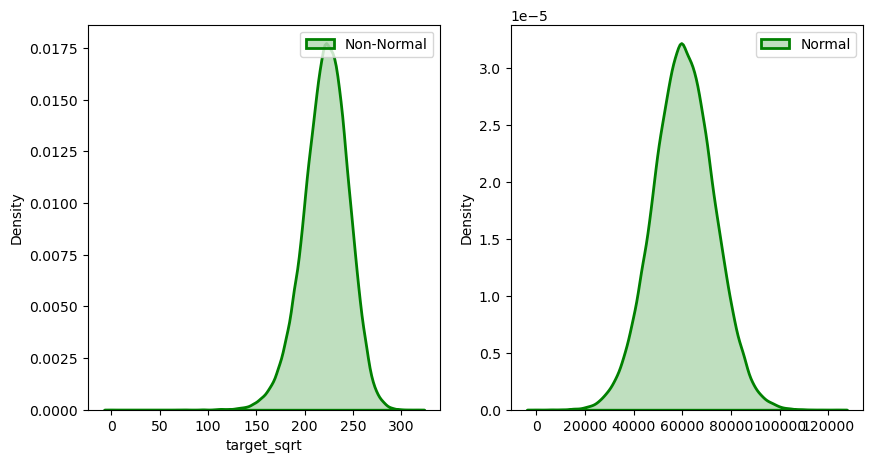

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(10, 5))

sns.kdeplot(data=pd_tt['target_sqrt'], fill=True, linewidth=2,
            label="Non-Normal", color="green", ax=ax[0])

sns.kdeplot(data=fitted_data_target, fill=True, linewidth=2,
            label="Normal", color="green", ax=ax[1])

ax[0].legend(loc="upper right")
ax[1].legend(loc="upper right")

print(f"Lambda value used for target transformation: {fitted_data_target}")
plt.show()

Lambda value used for target transformation: [55.76483369 68.96832161 59.76421085 ... 60.87831275 83.44087693
 46.66044023]


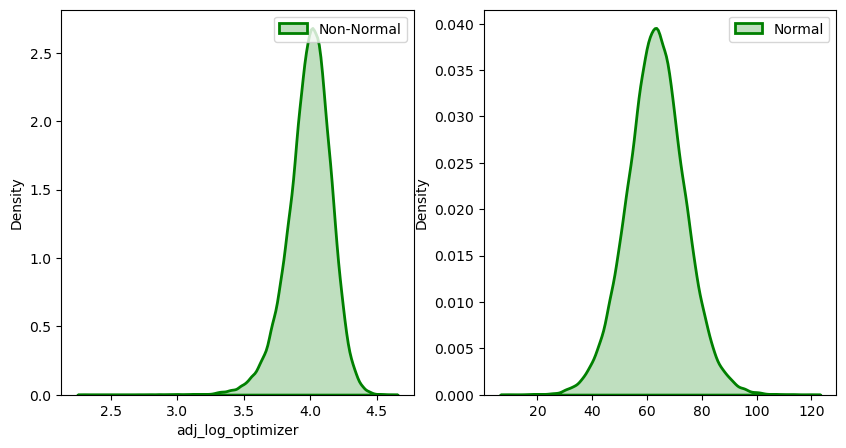

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(10, 5))

sns.kdeplot(data=pd_tt['adj_log_optimizer'], fill=True, linewidth=2,
            label="Non-Normal", color="green", ax=ax[0])

sns.kdeplot(data=fitted_data_optimizer, fill=True, linewidth=2,
            label="Normal", color="green", ax=ax[1])

ax[0].legend(loc="upper right")
ax[1].legend(loc="upper right")

print(f"Lambda value used for target transformation: {fitted_data_optimizer}")
plt.show()

In [14]:
pd_tt['bc_target_sqrt'] = fitted_data_target
pd_tt['bc_adj_log_optimizer'] = fitted_data_optimizer

In [15]:
pd_tt.head(3)

,index,0,1,2,3,4,5,6,7,8,...,scaled_target,scaled_optimizer,adj_log_target,adj_log_optimizer,target_sqrt,optimizer_sqrt,target_cbrt,optimizer_cbrt,bc_target_sqrt,bc_adj_log_optimizer
timestamp,,,,,,,,,,,,,,,,,,,,,
1997-01-05,0,1.354563,-2.403948,3.561855,0.527249,-1.228229,-3.703629,-1.032110,1.595900,0.516332,...,47780.444284,48.717564,10.774372,3.886040,218.587384,6.979797,36.286916,3.652261,58225.707249,55.764834
1997-01-05,1,1.042769,-3.835624,-0.479032,1.322611,-2.694026,-4.129116,-1.519565,-4.217741,-6.731050,...,64712.606382,59.438672,11.077711,4.084945,254.386726,7.709648,40.147912,3.902621,79344.654766,68.968322
1997-01-05,2,1.277779,1.801022,1.244291,-3.119853,0.484688,-3.046233,1.554053,3.414387,-1.593772,...,38458.502555,51.976927,10.557335,3.950800,196.108395,7.209503,33.754431,3.731959,46660.601536,59.764211


In [16]:
#mark first starts for cold start coverage
pd_tt['target_1s'] = 0

for i in range(pd_tt['index'].min(),pd_tt['index'].max()):
    min_ind = pd_tt[pd_tt['index']==i].idxmin()['bc_target_sqrt']
    pd_tt.loc[(pd_tt.index < min_ind) & (pd_tt['index']==i), 'target_1s'] = np.nan
    
pd_tt_1s = (pd_tt.dropna(subset=['target_1s'])).copy()
pd_tt_1s = pd_tt_1s.drop(['target','optimizer','scaled_target','scaled_optimizer','adj_log_target','adj_log_optimizer','target_sqrt','optimizer_sqrt','target_cbrt','optimizer_cbrt', 'target_1s'], axis=1).copy()
pd_tt_1s.columns = pd_tt_1s.columns.astype(str)

pd_tt = pd_tt.drop(['target','optimizer','scaled_target','scaled_optimizer','adj_log_target','adj_log_optimizer','target_sqrt','optimizer_sqrt','target_cbrt','optimizer_cbrt'], axis=1).copy()
pd_tt.columns = pd_tt.columns.astype(str)

In [17]:
pd_tt_1s.head(3)

,index,0,1,2,3,4,5,6,7,8,...,23,24,25,26,27,28,29,class,bc_target_sqrt,bc_adj_log_optimizer
timestamp,,,,,,,,,,,,,,,,,,,,,
1997-01-05,499,-0.039790,0.692131,0.667861,2.203861,-2.297917,1.573062,-1.974143,2.690614,-5.241490,...,3.738555,3.789523,3.115059,-0.681594,-8.470913,-2.000490,7.366775,26,65183.569249,61.276365
1997-01-12,98,-2.477883,-0.570847,-0.936970,-3.434987,0.682713,-2.909590,1.819769,-2.197454,-3.073770,...,3.445707,2.242546,0.914306,2.821087,-8.939843,1.179499,5.234260,48,25905.493524,69.353598
1997-01-12,374,1.826625,-0.858316,-1.724826,1.636263,-2.152607,0.841389,-6.046841,1.498579,0.424247,...,-0.035755,-6.824828,-1.088112,-2.058806,3.363880,-3.114604,-9.323948,13,37175.122546,61.340474


In [18]:
pd_tt_1s.index = pd.to_datetime(pd_tt_1s.index)

In [20]:
pd_tt_1s.to_csv(f'../{ds_name}.csv')